In [1]:

from google.colab import files
uploaded = files.upload()


Saving cedint_f1_hourly_clean.csv.gz to cedint_f1_hourly_clean.csv.gz


In [2]:

import pandas as pd

df = pd.read_csv("cedint_f1_hourly_clean.csv.gz")

df.head()


/tmp/ipykernel_678/1551254196.py:3: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("cedint_f1_hourly_clean.csv.gz")


,timestamp_utc,timestamp_local,zone,zone_code,load_type,n_devices,era,recommendation,usable_for_model,energy_wh_model,...,flag_temp_extreme,flag_hum_invalid,flag_lum_day_zero,series_excluded,n_zero_record,n_partial,n_reset,n_spike,n_neg_noise,n_neg_large
0,2020-04-02 23:00:00,2020-04-03 01:00:00,NE,1NE,HVAC,2,hourly,Use,1,3.841,...,0.0,0.0,0.0,0,0,0,0,0,0,0
1,2020-04-03 00:00:00,2020-04-03 02:00:00,NE,1NE,HVAC,2,hourly,Use,1,3.763,...,0.0,0.0,0.0,0,0,0,0,0,0,0
2,2020-04-03 01:00:00,2020-04-03 03:00:00,NE,1NE,HVAC,2,hourly,Use,1,3.683,...,0.0,0.0,0.0,0,0,0,0,0,0,0
3,2020-04-03 02:00:00,2020-04-03 04:00:00,NE,1NE,HVAC,2,hourly,Use,1,3.720,...,0.0,0.0,0.0,0,0,0,0,0,0,0
4,2020-04-03 03:00:00,2020-04-03 05:00:00,NE,1NE,HVAC,2,hourly,Use,1,3.775,...,0.0,0.0,0.0,0,0,0,0,0,0,0


In [3]:

# Convertiamo le date nel formato corretto
df["timestamp_local"] = pd.to_datetime(df["timestamp_local"])

# Selezioniamo solo i dati che ci interessano
nw_lighting = df[
    (df["zone"] == "NW") &
    (df["load_type"] == "Lighting") &
    (df["timestamp_local"].dt.year.isin([2021, 2022])) &
    (df["usable_for_model"] == 1)
].copy()

# Visualizziamo le prime 5 righe
nw_lighting[["timestamp_local", "lum_lux", "energy_wh_model"]].head()


,timestamp_local,lum_lux,energy_wh_model
140702,2021-01-01 00:00:00,0.0,810.705
140703,2021-01-01 01:00:00,0.0,843.863
140704,2021-01-01 02:00:00,0.0,872.226
140705,2021-01-01 03:00:00,0.0,849.941
140706,2021-01-01 04:00:00,0.0,795.738


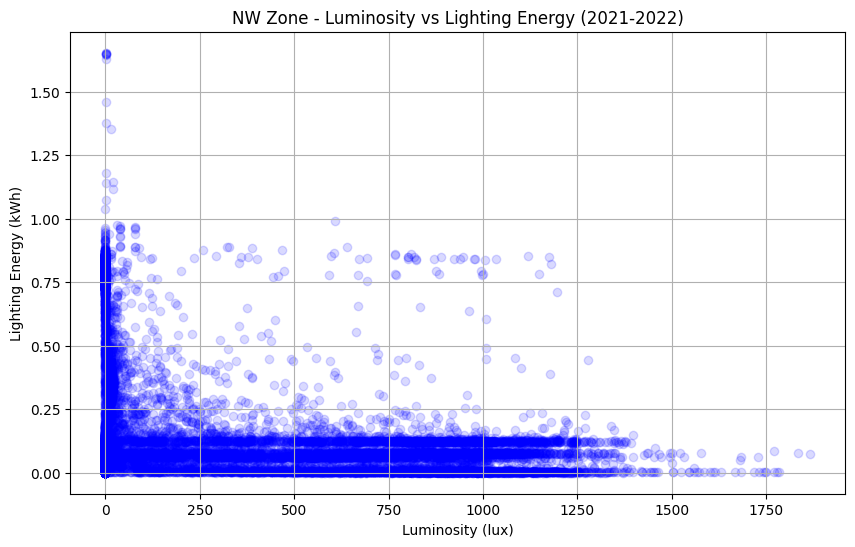

In [4]:

import matplotlib.pyplot as plt

# Selezioniamo le due variabili da analizzare
dati_grafico = nw_lighting[["lum_lux", "energy_wh_model"]].copy()

# Teniamo solo i valori numerici
dati_grafico["lum_lux"] = pd.to_numeric(
    dati_grafico["lum_lux"], errors="coerce"
)

dati_grafico["energy_wh_model"] = pd.to_numeric(
    dati_grafico["energy_wh_model"], errors="coerce"
)

# Eliminiamo le righe senza una delle due misurazioni
dati_grafico = dati_grafico.dropna()

# Convertiamo l'energia da Wh a kWh
dati_grafico["energy_kwh"] = dati_grafico["energy_wh_model"] / 1000

# Creiamo il grafico
plt.figure(figsize=(10, 6))

plt.scatter(
    dati_grafico["lum_lux"],
    dati_grafico["energy_kwh"],
    alpha=0.15,
    color="blue"
)

plt.title("NW Zone - Luminosity vs Lighting Energy (2021-2022)")
plt.xlabel("Luminosity (lux)")
plt.ylabel("Lighting Energy (kWh)")
plt.grid(True)

plt.show()


In [5]:

# Calcoliamo il coefficiente di correlazione
correlazione = dati_grafico["lum_lux"].corr(
    dati_grafico["energy_kwh"]
)

# Mostriamo il risultato
print("Correlazione Luminosity vs Lighting Energy:")
print(round(correlazione, 3))

# Contiamo le osservazioni utilizzate
print("Numero di osservazioni:")
print(len(dati_grafico))


Correlazione Luminosity vs Lighting Energy:
-0.372
Numero di osservazioni:
17113


In [6]:

# Identifichiamo le osservazioni sospette
sospetti = nw_lighting.loc[
    dati_grafico.index, "flag_lum_day_zero"
] == 1

# Escludiamo temporaneamente queste osservazioni
dati_controllati = dati_grafico.loc[~sospetti].copy()

# Calcoliamo nuovamente la correlazione
nuova_correlazione = dati_controllati["lum_lux"].corr(
    dati_controllati["energy_kwh"]
)

print("Osservazioni sospette:", sospetti.sum())
print("Osservazioni rimaste:", len(dati_controllati))
print("Correlazione originale:", round(correlazione, 3))
print("Correlazione dopo il controllo:", round(nuova_correlazione, 3))


Osservazioni sospette: 0
Osservazioni rimaste: 17113
Correlazione originale: -0.372
Correlazione dopo il controllo: -0.372


P8.1 – Relationship between Luminosity and Lighting Energy

Objective

The objective of this analysis is to understand whether there is a relationship between luminosity and lighting energy consumption in the NW zone of the CeDInt building.

Methodology

We used cleaned hourly data from 2021 and 2022. We selected the NW zone and Lighting consumption, excluding observations with missing values. We created a scatter plot and calculated the Pearson correlation coefficient.

Results

The analysis includes 17,113 hourly observations. The Pearson correlation coefficient is −0.372, showing a moderate negative linear relationship between luminosity and lighting energy consumption.

The scatter plot shows that higher luminosity is generally associated with lower lighting consumption. However, the points are quite dispersed, so the relationship is not very strong.

Data quality check

We checked the flag_lum_day_zero variable to identify suspicious zero-luminosity readings during daytime hours. No observations were flagged in the selected dataset, so the correlation remained unchanged.

Interpretation

The results suggest that luminosity may be associated with lighting energy consumption. However, other factors, such as the time of day and building occupancy, may also influence consumption. Therefore, this correlation does not demonstrate a direct cause-and-effect relationship.

In [7]:

# Controlliamo i valori della presenza
print("Valori della variabile occupancy:")

print(nw_lighting["occupancy"].value_counts(dropna=False))

# Visualizziamo le prime 5 osservazioni
nw_lighting[["timestamp_local", "occupancy", "energy_wh_model"]].head()


Valori della variabile occupancy:
occupancy
0.0    8951
1.0    8166
NaN     403
Name: count, dtype: int64


,timestamp_local,occupancy,energy_wh_model
140702,2021-01-01 00:00:00,0.0,810.705
140703,2021-01-01 01:00:00,0.0,843.863
140704,2021-01-01 02:00:00,0.0,872.226
140705,2021-01-01 03:00:00,1.0,849.941
140706,2021-01-01 04:00:00,0.0,795.738


In [8]:

# Selezioniamo le ore con presenza ed energia disponibili
occupancy_data = nw_lighting[
    (nw_lighting["occupancy"].isin([0, 1])) &
    (nw_lighting["energy_wh_model"].notna())
].copy()

# Convertiamo l'energia da Wh a kWh
occupancy_data["lighting_kwh"] = (
    occupancy_data["energy_wh_model"] / 1000
)

# Calcoliamo il consumo medio per ciascun valore di presenza
consumo_medio = occupancy_data.groupby("occupancy")[
    "lighting_kwh"
].agg(["mean", "count"])

# Visualizziamo i risultati
print(consumo_medio.round(3))


            mean  count
occupancy              
0.0        0.196   8951
1.0        0.171   8162


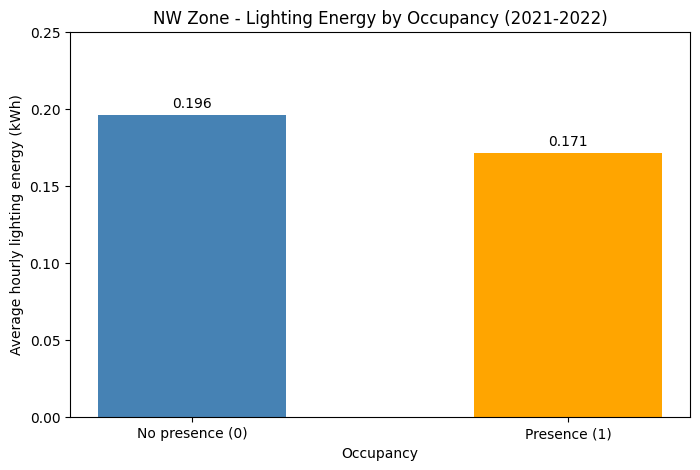

In [9]:

# Creiamo il grafico a barre

plt.figure(figsize=(8, 5))

# Definiamo i due gruppi
gruppi = ["No presence (0)", "Presence (1)"]

# Prendiamo i consumi medi calcolati
valori = consumo_medio.loc[[0.0, 1.0], "mean"]

# Disegniamo le barre
barre = plt.bar(
    gruppi,
    valori,
    color=["steelblue", "orange"],
    width=0.5
)

# Aggiungiamo titolo e nomi degli assi
plt.title("NW Zone - Lighting Energy by Occupancy (2021-2022)")
plt.xlabel("Occupancy")
plt.ylabel("Average hourly lighting energy (kWh)")

# Facciamo partire l'asse verticale da zero
plt.ylim(0, 0.25)

# Scriviamo il valore sopra ogni barra
for barra in barre:
    altezza = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width()/2,
        altezza + 0.005,
        f"{altezza:.3f}",
        ha="center"
    )

plt.show()


P8.2 – Relationship between Occupancy and Lighting Energy

Objective

The objective of this analysis is to understand whether lighting energy consumption changes depending on the presence of people in the NW zone.

Methodology

We used cleaned hourly data from 2021 and 2022. We divided the observations into two groups: occupancy = 0 (no presence detected) and occupancy = 1 (presence detected). We calculated the average hourly lighting energy consumption for each group and represented the results using a bar chart.

Results

The average hourly lighting energy consumption is 0.196 kWh when no presence is detected and 0.171 kWh when presence is detected.

This means that average lighting energy consumption is approximately 13% lower when presence is detected.

Interpretation

At first, this result seems surprising because we might expect higher lighting consumption when people are present.

However, our further analysis in P8.7 shows that the relationship changes when we consider the time of day. During both the selected daytime and nighttime periods, average lighting consumption is slightly higher when occupancy is detected.

This suggests that the time of day may influence the overall results. Therefore, occupancy should be analysed together with other variables, such as time and luminosity.

We cannot conclude that occupancy directly causes lower lighting energy consumption.

In [10]:

# P8.3 - Occupancy vs Plugs & Sockets

# Selezioniamo i dati della zona NW, anni 2021-2022
nw_plugs = df[
    (df["zone"] == "NW") &
    (df["load_type"] == "Plugs & Sockets") &
    (df["timestamp_local"].dt.year.isin([2021, 2022])) &
    (df["usable_for_model"] == 1)
].copy()

# Visualizziamo le prime 5 righe
nw_plugs[["timestamp_local", "occupancy", "energy_wh_model"]].head()


,timestamp_local,occupancy,energy_wh_model
167532,2021-01-01 00:00:00,0.0,705.5105
167533,2021-01-01 01:00:00,0.0,518.9330
167534,2021-01-01 02:00:00,0.0,464.8975
167535,2021-01-01 03:00:00,1.0,479.0425
167536,2021-01-01 04:00:00,0.0,1131.0930


In [11]:

# Manteniamo le osservazioni con presenza valida
plugs_data = nw_plugs[
    (nw_plugs["occupancy"].isin([0, 1])) &
    (nw_plugs["energy_wh_model"].notna())
].copy()

# Convertiamo l'energia da Wh a kWh
plugs_data["plugs_kwh"] = (
    plugs_data["energy_wh_model"] / 1000
)

# Calcoliamo il consumo medio per presenza e assenza
consumo_medio_plugs = plugs_data.groupby("occupancy")[
    "plugs_kwh"
].agg(["mean", "count"])

# Visualizziamo la tabella
print(consumo_medio_plugs.round(3))


            mean  count
occupancy              
0.0        1.248   8951
1.0        1.308   8164


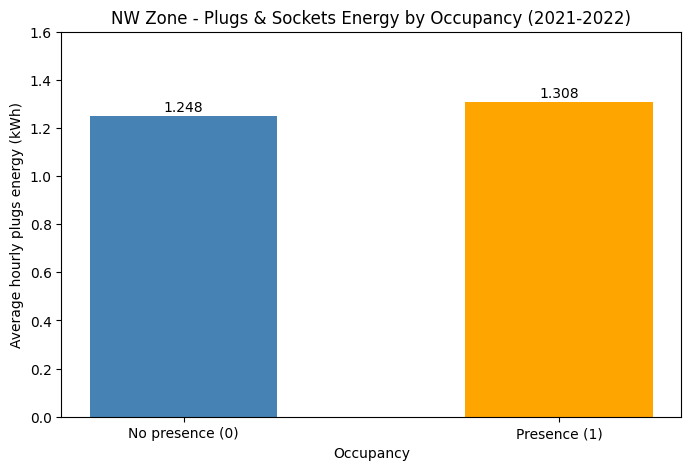

In [12]:

# P8.3 - Occupancy vs Plugs & Sockets

# Creiamo il grafico
plt.figure(figsize=(8, 5))

# Definiamo i due gruppi
gruppi = ["No presence (0)", "Presence (1)"]

# Prendiamo i consumi medi calcolati
valori = consumo_medio_plugs.loc[[0.0, 1.0], "mean"]

# Creiamo le barre
barre = plt.bar(
    gruppi,
    valori,
    color=["steelblue", "orange"],
    width=0.5
)

# Aggiungiamo titolo e nomi degli assi
plt.title("NW Zone - Plugs & Sockets Energy by Occupancy (2021-2022)")
plt.xlabel("Occupancy")
plt.ylabel("Average hourly plugs energy (kWh)")

# Impostiamo l'asse verticale partendo da zero
plt.ylim(0, 1.6)

# Scriviamo il valore sopra ogni barra
for barra in barre:
    altezza = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width()/2,
        altezza + 0.02,
        f"{altezza:.3f}",
        ha="center"
    )

# Mostriamo il grafico
plt.show()


P8.3 – Relationship between Occupancy and Plugs & Sockets Energy

Objective

The objective of this analysis is to understand whether the presence of people is associated with changes in the energy consumption of electrical devices in the NW zone.

Methodology

We used cleaned hourly data from 2021 and 2022. We divided the observations into two groups: occupancy = 0 (no presence detected) and occupancy = 1 (presence detected). We calculated the average hourly energy consumption for each group and represented the results using a bar chart.

Results

The average hourly energy consumption is 1.248 kWh when no presence is detected and 1.308 kWh when presence is detected.

This means that energy consumption is approximately 4.8% higher when presence is detected.

Interpretation

The results suggest that the presence of people may be associated with higher energy consumption from electrical devices, such as computers and monitors.

However, the difference is relatively small, and energy consumption remains high even when no presence is detected. This could indicate that some electrical devices remain active even when people are not present.

Other factors, such as the time of day and equipment usage, may also influence consumption. Therefore, we cannot conclude that occupancy directly causes the increase in energy consumption.

In [13]:

# P8.4 - Temperature vs HVAC Energy

# Selezioniamo la zona NW e gli anni 2021-2022
nw_hvac = df[
    (df["zone"] == "NW") &
    (df["load_type"] == "HVAC") &
    (df["timestamp_local"].dt.year.isin([2021, 2022])) &
    (df["usable_for_model"] == 1)
].copy()

# Visualizziamo le prime 5 osservazioni
nw_hvac[["timestamp_local", "temp_c", "energy_wh_model"]].head()


,timestamp_local,temp_c,energy_wh_model
87042,2021-01-01 00:00:00,13.344,163.5170
87043,2021-01-01 01:00:00,13.189,161.6080
87044,2021-01-01 02:00:00,13.136,161.6635
87045,2021-01-01 03:00:00,12.947,164.4325
87046,2021-01-01 04:00:00,13.063,168.5155


In [14]:

# P8.4 - Preparazione dei dati Temperature vs HVAC

# Selezioniamo le colonne necessarie
hvac_data = nw_hvac[
    ["timestamp_local", "temp_c", "energy_wh_model"]
].copy()

# Controlliamo che temperatura ed energia siano numeriche
hvac_data["temp_c"] = pd.to_numeric(
    hvac_data["temp_c"], errors="coerce"
)

hvac_data["energy_wh_model"] = pd.to_numeric(
    hvac_data["energy_wh_model"], errors="coerce"
)

# Eliminiamo le osservazioni senza temperatura o energia
hvac_data = hvac_data.dropna(
    subset=["temp_c", "energy_wh_model"]
)

# Convertiamo l'energia da Wh a kWh
hvac_data["hvac_kwh"] = hvac_data["energy_wh_model"] / 1000

# Controlliamo il numero di osservazioni disponibili
print("Numero di osservazioni:", len(hvac_data))

# Visualizziamo le prime 5 righe
hvac_data[["temp_c", "hvac_kwh"]].head()


Numero di osservazioni: 15957


,temp_c,hvac_kwh
87042,13.344,0.163517
87043,13.189,0.161608
87044,13.136,0.161663
87045,12.947,0.164433
87046,13.063,0.168516


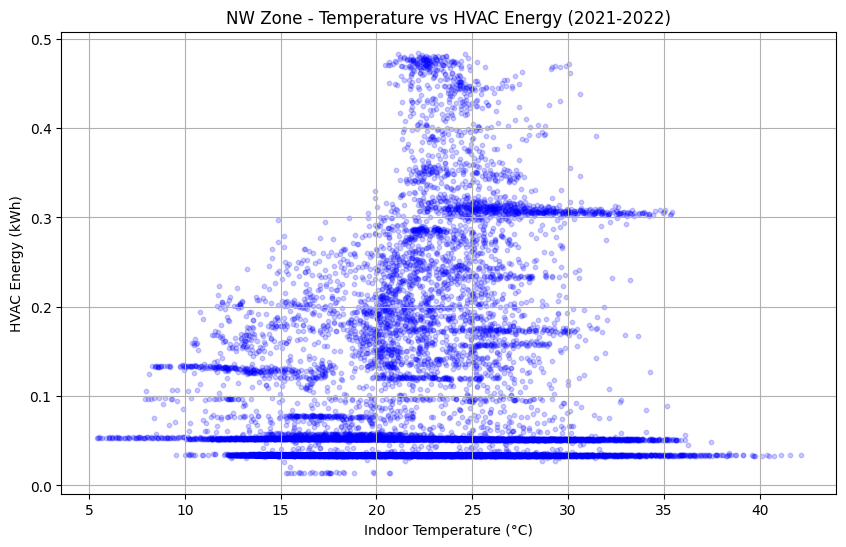

In [15]:

# P8.4 - Temperature vs HVAC Energy

# Creiamo lo spazio per il grafico
plt.figure(figsize=(10, 6))

# Creiamo lo scatter plot
plt.scatter(
    hvac_data["temp_c"],
    hvac_data["hvac_kwh"],
    alpha=0.2,
    s=10,
    color="blue"
)

# Aggiungiamo il titolo
plt.title("NW Zone - Temperature vs HVAC Energy (2021-2022)")

# Aggiungiamo i nomi degli assi
plt.xlabel("Indoor Temperature (°C)")
plt.ylabel("HVAC Energy (kWh)")

# Aggiungiamo la griglia
plt.grid(True)

# Mostriamo il grafico
plt.show()


In [16]:

# P8.4 - Correlazione Temperature vs HVAC Energy

# Calcoliamo la correlazione
correlazione_hvac = hvac_data["temp_c"].corr(
    hvac_data["hvac_kwh"]
)

# Mostriamo il risultato
print("Temperature vs HVAC Energy")
print("Pearson correlation:", round(correlazione_hvac, 3))

# Numero di osservazioni utilizzate
print("Number of observations:", len(hvac_data))


Temperature vs HVAC Energy
Pearson correlation: 0.174
Number of observations: 15957


In [17]:

# P8.4 - Consumo medio HVAC per intervalli di temperatura

# Creiamo una copia dei dati
temp_data = hvac_data.copy()

# Dividiamo le temperature in intervalli di 2 gradi
temp_data["intervallo_temp"] = pd.cut(
    temp_data["temp_c"],
    bins=range(0, 54, 2),
    right=False
)

# Calcoliamo il consumo medio per ogni intervallo
consumo_per_temp = temp_data.groupby(
    "intervallo_temp",
    observed=True
)["hvac_kwh"].agg(["mean", "count"])

# Mostriamo i risultati
print(consumo_per_temp.round(3))


                  mean  count
intervallo_temp              
[4, 6)           0.054      6
[6, 8)           0.056     34
[8, 10)          0.087     72
[10, 12)         0.094    197
[12, 14)         0.067    721
[14, 16)         0.052   1592
[16, 18)         0.056   1781
[18, 20)         0.062   1849
[20, 22)         0.099   2307
[22, 24)         0.139   2198
[24, 26)         0.129   1973
[26, 28)         0.114   1395
[28, 30)         0.099    864
[30, 32)         0.089    494
[32, 34)         0.085    275
[34, 36)         0.068    133
[36, 38)         0.035     43
[38, 40)         0.034     16
[40, 42)         0.034      6
[42, 44)         0.034      1


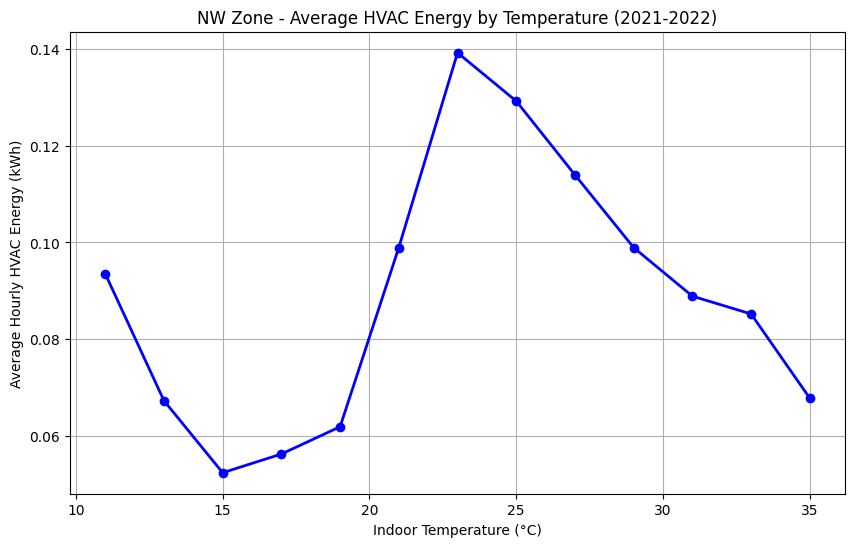

In [18]:

# P8.4 - Average HVAC Energy by Temperature Range

# Selezioniamo gli intervalli con almeno 100 osservazioni
dati_intervalli = consumo_per_temp[
    consumo_per_temp["count"] >= 100
].copy()

# Calcoliamo il valore centrale di ogni intervallo
dati_intervalli["temperatura_centrale"] = [
    intervallo.mid for intervallo in dati_intervalli.index
]

# Creiamo il grafico
plt.figure(figsize=(10, 6))

plt.plot(
    dati_intervalli["temperatura_centrale"],
    dati_intervalli["mean"],
    marker="o",
    color="blue",
    linewidth=2
)

# Aggiungiamo titolo e nomi degli assi
plt.title("NW Zone - Average HVAC Energy by Temperature (2021-2022)")
plt.xlabel("Indoor Temperature (°C)")
plt.ylabel("Average Hourly HVAC Energy (kWh)")

# Aggiungiamo la griglia
plt.grid(True)

# Mostriamo il grafico
plt.show()


P8.4 – Relationship between Temperature and HVAC Energy Consumption

Objective

The objective of this analysis is to understand the relationship between indoor temperature and HVAC energy consumption in the NW zone of the CeDInt building.

Methodology

We used cleaned hourly data from 2021 and 2022, with 15,957 valid observations. First, we created a scatter plot to study the relationship between temperature and HVAC energy consumption. Then, we calculated the Pearson correlation coefficient.

To better understand the relationship, we also divided temperatures into intervals of 2°C and calculated the average HVAC consumption for each interval. For the second graph, we selected intervals with at least 100 observations.

Results

The Pearson correlation coefficient is +0.174, indicating a weak positive linear relationship between indoor temperature and HVAC energy consumption.

However, the second graph shows a non-linear pattern. Average HVAC consumption increases between approximately 15°C and 23°C, reaching its highest value of about 0.139 kWh in the 22–24°C interval. After this point, average consumption generally decreases as temperature increases.

Interpretation

The results suggest that the relationship between indoor temperature and HVAC energy consumption is not simply linear and does not show a clear U-shaped pattern.

The highest average consumption is observed at intermediate temperatures. This may be related to the operating conditions of the HVAC system, building occupancy or other factors.

Since we are analysing indoor temperature, which can also be influenced by the HVAC system, we cannot conclude that temperature directly causes these changes in energy consumption.

In [19]:

# P8.5 - Humidity vs HVAC Energy

# Selezioniamo le colonne necessarie
humidity_data = nw_hvac[
    ["timestamp_local", "hum_pct", "energy_wh_model"]
].copy()

# Controlliamo che umidità ed energia siano numeriche
humidity_data["hum_pct"] = pd.to_numeric(
    humidity_data["hum_pct"], errors="coerce"
)

humidity_data["energy_wh_model"] = pd.to_numeric(
    humidity_data["energy_wh_model"], errors="coerce"
)

# Escludiamo le osservazioni con valori mancanti
humidity_data = humidity_data.dropna(
    subset=["hum_pct", "energy_wh_model"]
)

# Convertiamo l'energia da Wh a kWh
humidity_data["hvac_kwh"] = (
    humidity_data["energy_wh_model"] / 1000
)

# Contiamo le osservazioni disponibili
print("Number of observations:", len(humidity_data))

# Visualizziamo le prime 5 righe
humidity_data[["hum_pct", "hvac_kwh"]].head()


Number of observations: 15957


,hum_pct,hvac_kwh
87042,31.0,0.163517
87043,30.0,0.161608
87044,31.0,0.161663
87045,30.0,0.164433
87046,31.0,0.168516


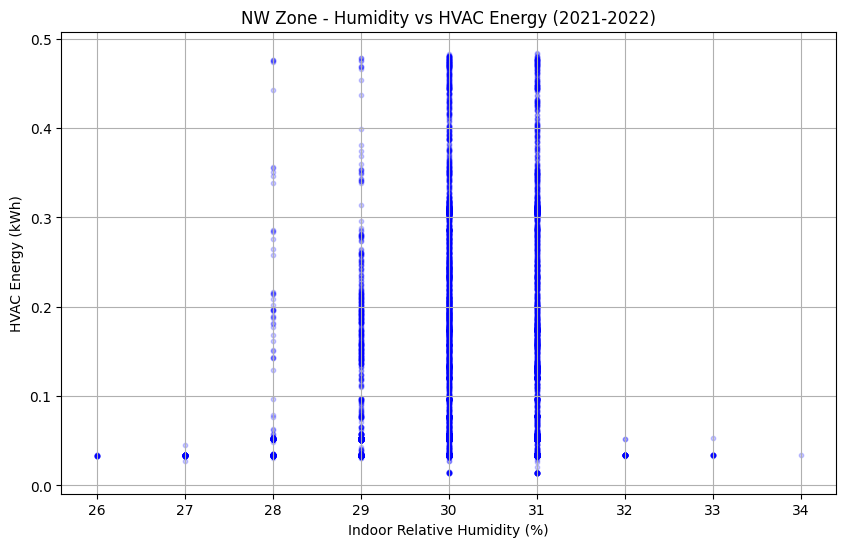

In [20]:

# P8.5 - Humidity vs HVAC Energy

# Creiamo lo spazio per il grafico
plt.figure(figsize=(10, 6))

# Creiamo lo scatter plot
plt.scatter(
    humidity_data["hum_pct"],
    humidity_data["hvac_kwh"],
    alpha=0.2,
    s=10,
    color="blue"
)

# Inseriamo il titolo
plt.title("NW Zone - Humidity vs HVAC Energy (2021-2022)")

# Inseriamo i nomi degli assi
plt.xlabel("Indoor Relative Humidity (%)")
plt.ylabel("HVAC Energy (kWh)")

# Aggiungiamo la griglia
plt.grid(True)

# Mostriamo il grafico
plt.show()


In [21]:

# P8.5 - Correlation between Humidity and HVAC Energy

# Calcoliamo la correlazione di Pearson
correlazione_humidity = humidity_data["hum_pct"].corr(
    humidity_data["hvac_kwh"]
)

# Mostriamo il risultato
print("Humidity vs HVAC Energy")
print("Pearson correlation:", round(correlazione_humidity, 3))
print("Number of observations:", len(humidity_data))

# Controlliamo i valori di umidità
print("\nHumidity values and number of observations:")
print(humidity_data["hum_pct"].value_counts().sort_index())


Humidity vs HVAC Energy
Pearson correlation: 0.059
Number of observations: 15957

Humidity values and number of observations:
hum_pct
26.0      13
27.0      63
28.0     319
29.0    1288
30.0    8429
31.0    5798
32.0      34
33.0      12
34.0       1
Name: count, dtype: int64


P8.5 – Relationship between Humidity and HVAC Energy Consumption

Objective

The objective of this analysis is to understand whether indoor humidity is associated with HVAC energy consumption in the NW zone of the CeDInt building.

Methodology

We used cleaned hourly data from 2021 and 2022, with 15,957 valid observations. We created a scatter plot to study the relationship between indoor relative humidity and HVAC energy consumption. We also calculated the Pearson correlation coefficient and examined the distribution of humidity values.

Results

The Pearson correlation coefficient is +0.059, indicating a very weak positive linear relationship between humidity and HVAC energy consumption.

The scatter plot does not show a clear increasing, decreasing or U-shaped pattern.

Furthermore, approximately 89% of the observations have humidity values of 30% or 31%. This means that humidity varies very little in the selected dataset.

Interpretation

The results suggest that indoor humidity has no clear linear association with HVAC energy consumption in the analysed data.

However, the limited variation in humidity makes it difficult to identify possible relationships. HVAC consumption may also depend on other factors, such as temperature, occupancy and the operating conditions of the system.

Therefore, we cannot conclude that humidity has no effect on HVAC energy consumption.

In [22]:

# P8.6 - Occupancy by Hour of the Day

# Selezioniamo le osservazioni con presenza valida
presenza_oraria = nw_lighting[
    nw_lighting["occupancy"].isin([0, 1])
].copy()

# Estraiamo l'ora dalla data
presenza_oraria["hour"] = (
    presenza_oraria["timestamp_local"].dt.hour
)

# Calcoliamo la percentuale di presenza per ogni ora
presenza_per_ora = presenza_oraria.groupby("hour")[
    "occupancy"
].agg(["mean", "count"])

# Convertiamo la media in percentuale
presenza_per_ora["presence_percentage"] = (
    presenza_per_ora["mean"] * 100
)

# Visualizziamo i risultati
print(
    presenza_per_ora[
        ["presence_percentage", "count"]
    ].round(1)
)


      presence_percentage  count
hour                            
0                    34.8    715
1                    33.8    715
2                    29.5    715
3                    34.1    715
4                    32.9    715
5                    37.3    713
6                    56.0    712
7                    51.3    708
8                    52.0    709
9                    58.4    712
10                   59.0    712
11                   61.9    711
12                   58.1    711
13                   59.3    712
14                   67.0    712
15                   59.3    713
16                   47.1    712
17                   49.9    715
18                   56.1    715
19                   43.8    715
20                   44.2    715
21                   38.7    715
22                   42.4    715
23                   38.5    715


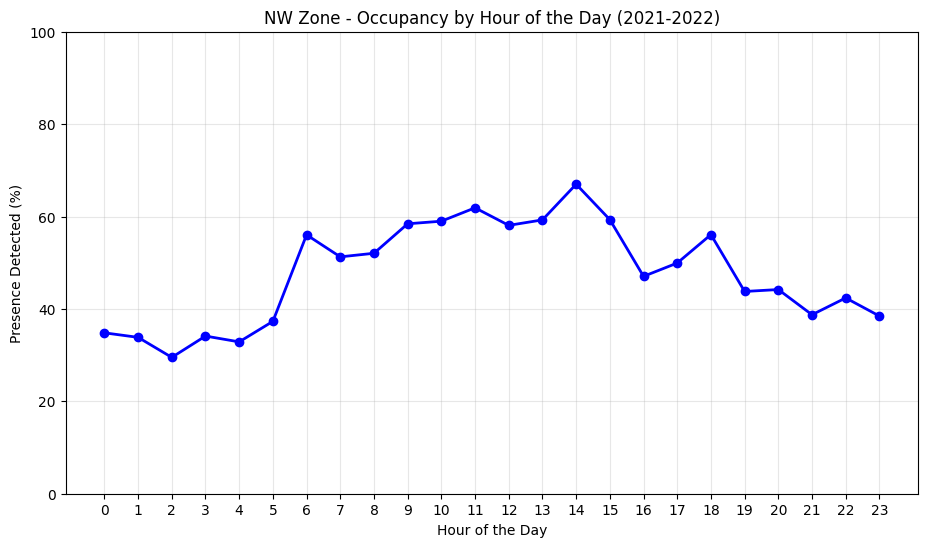

In [23]:

# P8.6 - Occupancy by Hour of the Day

# Creiamo lo spazio per il grafico
plt.figure(figsize=(11, 6))

# Disegniamo la linea della presenza
plt.plot(
    presenza_per_ora.index,
    presenza_per_ora["presence_percentage"],
    marker="o",
    color="blue",
    linewidth=2
)

# Aggiungiamo il titolo
plt.title("NW Zone - Occupancy by Hour of the Day (2021-2022)")

# Aggiungiamo i nomi degli assi
plt.xlabel("Hour of the Day")
plt.ylabel("Presence Detected (%)")

# Mostriamo tutte le 24 ore
plt.xticks(range(24))

# Impostiamo l'asse verticale
plt.ylim(0, 100)

# Aggiungiamo la griglia
plt.grid(True, alpha=0.3)

# Mostriamo il grafico
plt.show()


P8.6 – Occupancy by Hour of the Day

Objective

The objective of this analysis is to understand how detected occupancy changes during the day in the NW zone of the CeDInt building.

Methodology

We used cleaned hourly data from 2021 and 2022. We selected valid occupancy values (0 and 1) and calculated the percentage of observations with detected presence for each hour of the day. We represented the results using a line chart.

Results

The results show that detected occupancy generally increases during daytime hours.

The highest percentage is observed at 14:00, when occupancy is detected in 67% of the observations. During the night, the percentages are generally lower, reaching 29.5% at 02:00.

However, occupancy is also detected during nighttime hours.

Interpretation

The results suggest that detected occupancy follows a daily pattern, with higher percentages during the day.

This may help explain the relationship between occupancy and lighting energy consumption observed in the previous analysis, since daylight and the time of day could also influence lighting usage.

However, further analysis is needed to understand whether these factors explain the differences in energy consumption. Also, the nighttime occupancy readings should be interpreted with caution.

In [24]:

# P8.7 - Lighting Energy by Occupancy and Hour

# Selezioniamo le osservazioni con presenza valida
confronto = nw_lighting[
    nw_lighting["occupancy"].isin([0, 1])
].copy()

# Convertiamo l'energia in kWh
confronto["lighting_kwh"] = pd.to_numeric(
    confronto["energy_wh_model"], errors="coerce"
) / 1000

# Escludiamo le osservazioni senza consumo disponibile
confronto = confronto.dropna(subset=["lighting_kwh"])

# Estraiamo l'ora della giornata
confronto["hour"] = confronto["timestamp_local"].dt.hour

# Calcoliamo il consumo medio per ogni ora e presenza
medie_orarie = confronto.groupby(
    ["hour", "occupancy"]
)["lighting_kwh"].agg(["mean", "count"]).reset_index()

# Visualizziamo i primi risultati
print(medie_orarie.head(10).round(3))



   hour  occupancy   mean  count
0     0        0.0  0.315    466
1     0        1.0  0.320    249
2     1        0.0  0.258    473
3     1        1.0  0.355    242
4     2        0.0  0.269    504
5     2        1.0  0.283    211
6     3        0.0  0.238    471
7     3        1.0  0.332    244
8     4        0.0  0.251    480
9     4        1.0  0.305    235


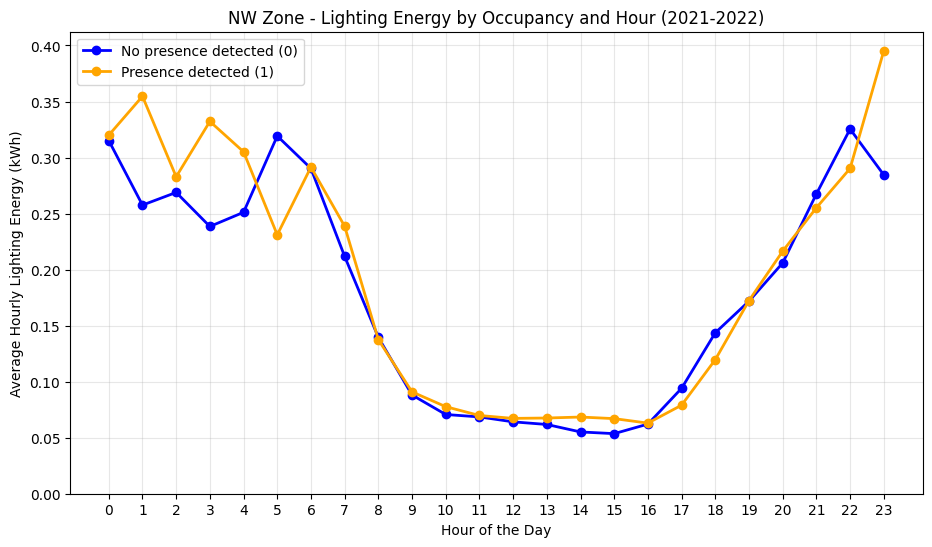

In [25]:

# Prepariamo la tabella per il grafico
tabella_grafico = medie_orarie.pivot(
    index="hour",
    columns="occupancy",
    values="mean"
)

# Creiamo lo spazio per il grafico
plt.figure(figsize=(11, 6))

# Prima linea: nessuna presenza rilevata
plt.plot(
    tabella_grafico.index,
    tabella_grafico[0.0],
    marker="o",
    color="blue",
    linewidth=2,
    label="No presence detected (0)"
)

# Seconda linea: presenza rilevata
plt.plot(
    tabella_grafico.index,
    tabella_grafico[1.0],
    marker="o",
    color="orange",
    linewidth=2,
    label="Presence detected (1)"
)

# Aggiungiamo titolo e assi
plt.title("NW Zone - Lighting Energy by Occupancy and Hour (2021-2022)")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Hourly Lighting Energy (kWh)")

# Mostriamo tutte le ore
plt.xticks(range(24))

# Impostiamo l'asse verticale da zero
plt.ylim(bottom=0)

# Aggiungiamo legenda e griglia
plt.legend()
plt.grid(True, alpha=0.3)

# Mostriamo il grafico
plt.show()


In [26]:

# P8.7 - Confronto tra giorno e notte

# Selezioniamo le ore diurne (09:00-17:59)
giorno = confronto[
    confronto["hour"].between(9, 17)
]

# Selezioniamo le ore notturne (00:00-05:59)
notte = confronto[
    confronto["hour"].between(0, 5)
]

# Consumi medi durante il giorno
print("DAYTIME - Lighting Energy by Occupancy")
print(
    giorno.groupby("occupancy")["lighting_kwh"]
    .agg(["mean", "count"]).round(3)
)

# Consumi medi durante la notte
print("\nNIGHTTIME - Lighting Energy by Occupancy")
print(
    notte.groupby("occupancy")["lighting_kwh"]
    .agg(["mean", "count"]).round(3)
)


DAYTIME - Lighting Energy by Occupancy
            mean  count
occupancy              
0.0        0.069   2707
1.0        0.072   3699

NIGHTTIME - Lighting Energy by Occupancy
            mean  count
occupancy              
0.0        0.274   2841
1.0        0.304   1447


P8.7 – Lighting Energy by Occupancy and Hour
Objective

The objective of this analysis is to understand whether the relationship between occupancy and lighting energy consumption changes depending on the hour of the day.

Methodology

We used cleaned hourly data from 2021 and 2022 for the NW zone. We calculated the average lighting energy consumption for each hour, comparing observations with and without detected occupancy.

We created a line chart with two lines and then compared daytime hours (09:00–17:59) and nighttime hours (00:00–05:59).

Results

The line chart shows that lighting energy consumption changes significantly during the day. Consumption is generally higher at night and lower during daytime hours.

During daytime hours, average consumption is 0.069 kWh without detected occupancy and 0.072 kWh with detected occupancy.

During nighttime hours, average consumption is 0.274 kWh without detected occupancy and 0.304 kWh with detected occupancy.

Therefore, in both periods, average lighting consumption is slightly higher when occupancy is detected.

Interpretation

These results are interesting because our previous analysis (P8.2) showed lower average lighting consumption when occupancy was detected.

However, after separating daytime and nighttime observations, we find the opposite pattern in both periods.

This suggests that the time of day may influence the relationship between occupancy and lighting consumption. The different distribution of occupied and unoccupied hours could partly explain the original result.

Therefore, occupancy should not be analysed independently from other variables, especially the hour of the day and luminosity.

This analysis does not demonstrate a direct causal relationship, and the remaining hours and other factors should also be considered.

P8 – General Conclusions and Insights for Forecasting

General Conclusions

The objective of P8 was to explore the relationship between environmental variables, building occupancy and energy consumption.

We analysed cleaned hourly data from the NW zone of the CeDInt building during 2021–2022.

The analysis provided several interesting results.

First, luminosity shows a moderate negative correlation with lighting energy consumption (−0.372). This means that higher luminosity is generally associated with lower lighting consumption. However, other factors may also influence this relationship.

Second, building occupancy is associated with different energy consumption patterns. Plugs & Sockets consumption is approximately 4.8% higher when presence is detected. However, for Lighting, the relationship changes when we consider the hour of the day. This shows that occupancy should not be studied independently from time.

Third, temperature shows a weak positive linear correlation with HVAC consumption (+0.174). However, the analysis of average consumption by temperature interval shows a non-linear pattern, with the highest average consumption around 22–24°C.

Finally, humidity shows a very weak correlation with HVAC consumption (+0.059). Most humidity observations are concentrated around 30–31%, making it difficult to identify a clear relationship.

Insights for Forecasting

These results can provide useful information for the team responsible for forecasting energy consumption.

In particular, time of day, luminosity, temperature and occupancy could be useful variables to consider when developing prediction models.

It may also be important to analyse combinations of variables, since their relationships with energy consumption can change depending on the operating conditions of the building.

However, the correlations found in this exploratory analysis do not demonstrate causality. Further analysis is necessary to understand which variables actually improve prediction accuracy.

Limitations

This initial analysis focuses on the NW zone during 2021–2022. Therefore, the results cannot automatically be generalised to the other zones or to 2025.

Some observations are also missing, and the environmental sensors have limitations, particularly for humidity and occupancy measurements.

Final Considerations

Overall, the exploratory analysis suggests that energy consumption is associated with several environmental and occupancy-related variables, but the relationships are not always simple or linear.

These findings provide a useful starting point for further analysis and the development of energy forecasting models.